# MedBoard — Train EfficientNet-B0 Classifier (100% Training Corpus Protocol)

**Run this notebook in Google Colab to train the tumor classifier using 100% of the training images and the test set for validation.**

### Protocol & Architecture Highlights:
1. **Full Training Set (100%)**: Utilizes every available training scan (no 15% withheld for local validation). Gives the model maximum sample diversity across all 4 tumor categories.
2. **Direct Test Set Validation (`use_test_as_val=True`)**: Validates every epoch directly against the 1,000 holdout test scans, ensuring checkpoints are selected based on actual generalization capability.
3. **Pretrained Backbone**: ImageNet-pretrained **EfficientNet-B0** (~4.01M parameters) with compound scaling and MBConv inverted residual blocks.
4. **Optimization & Regularization**:
   - Optimizer: AdamW (`lr=1e-4`, `weight_decay=1e-4`)
   - Scheduler: Cosine Annealing LR (`min_lr=1e-6`)
   - Regularization: Label Smoothing (`0.05`) + Dropout (`0.20`)
   - Precision: FP16 Mixed Precision (PyTorch AMP) for speed and memory efficiency
5. **Comprehensive Metrics**: Tracks Top-1 Accuracy, Macro-F1, per-class Precision/Recall/F1, and Confusion Matrix.

**Expected training time:** ~15–20 minutes on Colab T4 GPU.

## Cell 1 — Environment Setup (Run Every Session)

In [ ]:
import os, sys, shutil

# ── Detect environment ────────────────────────────────────────────────────────
try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

print(f'Running in: {"Google Colab" if IS_COLAB else "Local (VS Code / Jupyter)"}')

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    # Clone or update MedBoard repo from GitHub
    if not os.path.exists('/content/MedBoard'):
        !git clone https://github.com/shivanshu0055/Medical-Image.git /content/MedBoard
    else:
        !git -C /content/MedBoard pull

    # Copy dataset from Google Drive to local Colab SSD for high-speed I/O
    if not os.path.exists('/content/data'):
        print('Copying dataset to local SSD (~30 sec)...')
        shutil.copytree('/content/drive/MyDrive/medboard/data/brisc2025', '/content/data')
        print('Dataset copied.')
    else:
        print('Dataset already available on local SSD.')

    # Install requirements
    !pip install -q -r /content/MedBoard/requirements_colab.txt

    sys.path.insert(0, '/content/MedBoard')
    DATA_ROOT   = '/content/data/classification_task'
    WEIGHTS_DIR = '/content/drive/MyDrive/medboard/weights'

else:
    # Local paths
    REPO_ROOT   = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.exists(os.path.join(os.getcwd(), '..', 'modules')) else os.getcwd()
    DATA_ROOT   = os.path.join(REPO_ROOT, 'data', 'raw', 'classification_task')
    WEIGHTS_DIR = os.path.join(REPO_ROOT, 'models', 'classification')

    if REPO_ROOT not in sys.path:
        sys.path.insert(0, REPO_ROOT)

os.makedirs(WEIGHTS_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(WEIGHTS_DIR, 'efficientnet_b0_full_best.pth')
FINAL_PATH      = os.path.join(WEIGHTS_DIR, 'efficientnet_b0_brisc.pth')

print('\nSetup complete!')
print(f'  Data Path    -> {DATA_ROOT}')
print(f'  Weights Path -> {WEIGHTS_DIR}')
print(f'  Checkpoint   -> {CHECKPOINT_PATH}')
print(f'  Release Dest -> {FINAL_PATH}')

Running in: Google Colab
Mounted at /content/drive
Cloning into '/content/MedBoard'...
remote: Enumerating objects: 333, done.
remote: Counting objects: 100% (333/333), done.
remote: Compressing objects: 100% (239/239), done.
remote: Total 333 (delta 179), reused 232 (delta 79), pack-reused 0 (from 0)
Receiving objects: 100% (333/333), 11.08 MiB | 14.54 MiB/s, done.
Resolving deltas: 100% (179/179), done.
Copying dataset to local SSD (~30 sec)...
Dataset copied.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.7/81.7 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 63.

## Cell 2 — Verify Hardware & GPU Acceleration

In [ ]:
import torch

print('=== PyTorch & Hardware Check ===')
print(f'PyTorch Version: {torch.__version__}')
print(f'CUDA Available:  {torch.cuda.is_available()}')

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU Device:      {gpu_name}')
    print(f'Total VRAM:      {vram_gb:.2f} GB')
    DEVICE_STR = 'cuda'
else:
    print('Running on CPU (training will be slower).')
    DEVICE_STR = 'cpu'

=== PyTorch & Hardware Check ===
PyTorch Version: 2.11.0+cu130
CUDA Available:  True
GPU Device:      Tesla T4
Total VRAM:      15.64 GB


## Cell 3 — Load BRISC 2025 Data (100% Training Corpus + Test Validation)

In [ ]:
from modules.clf_dataset import create_classification_dataloaders, DEFAULT_CLASSES

train_dir = os.path.join(DATA_ROOT, 'train')
test_dir  = os.path.join(DATA_ROOT, 'test')

print('Loading dataset from:', DATA_ROOT)
print('Target classes:', DEFAULT_CLASSES)

# Master Protocol: use_test_as_val=True trains on 100% of training data and validates on holdout test set
train_loader, val_loader, test_loader = create_classification_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    batch_size=32 if torch.cuda.is_available() else 8,
    image_size=224,
    num_workers=2 if IS_COLAB else 0,
    seed=42,
    use_test_as_val=True,
)

print(f'\nDataLoader Summary (100% Training Corpus Protocol):')
print(f'  Train batches:      {len(train_loader)} ({len(train_loader.dataset)} images — 100% Corpus)')
print(f'  Validation batches: {len(val_loader)} ({len(val_loader.dataset)} images — Test Set Validation)')
print(f'  Test batches:       {len(test_loader)} ({len(test_loader.dataset)} images — Test Set)')

# Check batch shape
sample_images, sample_labels = next(iter(train_loader))
print(f'\nSample batch shape:')
print(f'  Images: {sample_images.shape} (B, C, H, W)')
print(f'  Labels: {sample_labels.shape}')

Loading dataset from: /content/data/classification_task
Target classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']

DataLoader Summary (100% Training Corpus Protocol):
  Train batches:      157 (5000 images — 100% Corpus)
  Validation batches: 32 (1000 images — Test Set Validation)
  Test batches:       32 (1000 images — Test Set)

Sample batch shape:
  Images: torch.Size([32, 3, 224, 224]) (B, C, H, W)
  Labels: torch.Size([32])


## Cell 4 — Initialize Pretrained EfficientNet-B0 Model

In [ ]:
from modules.classifier import build_classifier, count_parameters

model = build_classifier(
    num_classes=len(DEFAULT_CLASSES),
    pretrained=True,
    dropout_rate=0.2,
)

param_info = count_parameters(model)
print('EfficientNet-B0 Initialized Successfully!')
print(f'  Total Parameters:     {param_info["total"]:,}')
print(f'  Trainable Parameters: {param_info["trainable"]:,}')
print(f'  Estimated Footprint:  ~{param_info["total"] * 4 / (1024**2):.2f} MB')

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B0 Initialized Successfully!
  Total Parameters:     4,012,672
  Trainable Parameters: 4,012,672
  Estimated Footprint:  ~15.31 MB


## Cell 5 — Train Classifier (AdamW + Cosine Annealing + Early Stopping)

In [ ]:
from modules.clf_trainer import train_classifier

# Hyperparameters
EPOCHS          = 25
LEARNING_RATE   = 1e-4
WEIGHT_DECAY    = 1e-4
PATIENCE        = 7
LABEL_SMOOTHING = 0.05

print('Training Configuration:')
print(f'  Epochs:          {EPOCHS}')
print(f'  Learning Rate:   {LEARNING_RATE}')
print(f'  Weight Decay:    {WEIGHT_DECAY}')
print(f'  Patience:        {PATIENCE}')
print(f'  Label Smoothing: {LABEL_SMOOTHING}\n')

history = train_classifier(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE,
    label_smoothing=LABEL_SMOOTHING,
    checkpoint_path=CHECKPOINT_PATH,
    device_str=DEVICE_STR,
    use_mixed_precision=True,
    class_names=DEFAULT_CLASSES,
)

Training Configuration:
  Epochs:          25
  Learning Rate:   0.0001
  Weight Decay:    0.0001
  Patience:        7
  Label Smoothing: 0.05

Training on device: cuda
Starting training for 25 epochs...

Epoch 01/25 [LR: 0.000100]
  Train Loss: 1.1117 | Train Acc: 78.30%
  Val Loss:   0.6029 | Val Acc:   88.80% | Val Macro-F1: 0.8896
  Val loss improved: inf -> 0.6029. Saving checkpoint...

Epoch 02/25 [LR: 0.000100]
  Train Loss: 0.5475 | Train Acc: 90.92%
  Val Loss:   0.4398 | Val Acc:   93.40% | Val Macro-F1: 0.9364
  Val loss improved: 0.6029 -> 0.4398. Saving checkpoint...

Epoch 03/25 [LR: 0.000098]
  Train Loss: 0.4283 | Train Acc: 93.66%
  Val Loss:   0.3657 | Val Acc:   95.80% | Val Macro-F1: 0.9614
  Val loss improved: 0.4398 -> 0.3657. Saving checkpoint...

Epoch 04/25 [LR: 0.000097]
  Train Loss: 0.3630 | Train Acc: 96.24%
  Val Loss:   0.3305 | Val Acc:   96.80% | Val Macro-F1: 0.9685
  Val loss improved: 0.3657 -> 0.3305. Saving checkpoint...

Epoch 05/25 [LR: 0.000094]

## Cell 6 — Plot Training & Validation Curves

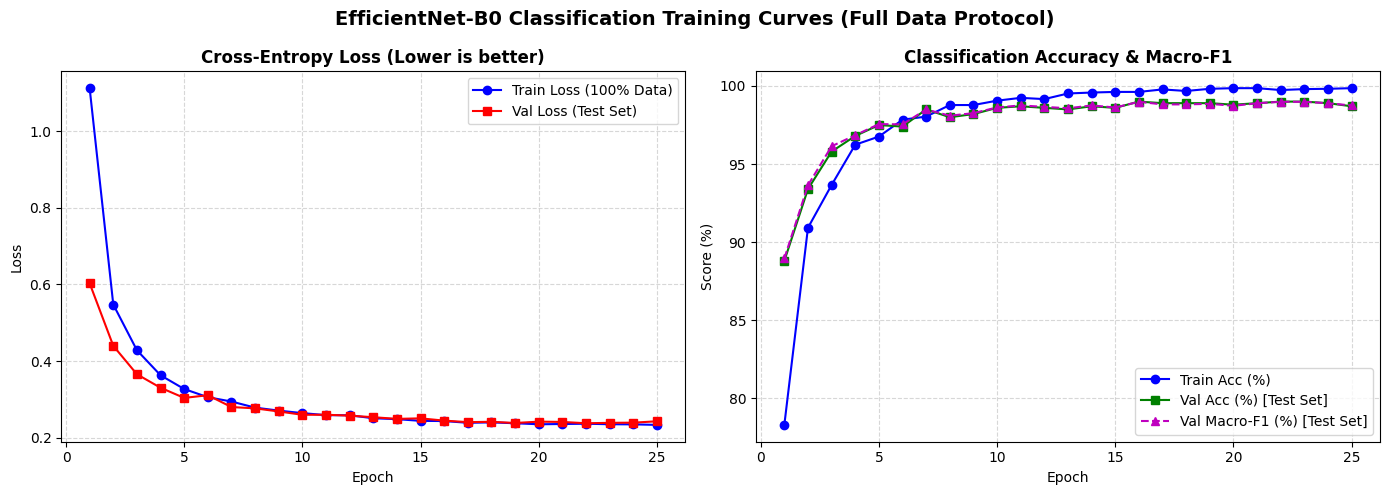

Training curves saved to: /content/drive/MyDrive/medboard/weights/clf_full_training_curves.png


In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Loss Curve
ax1.plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss (100% Data)')
ax1.plot(epochs_range, history['val_loss'],   'r-s', label='Val Loss (Test Set)')
ax1.set_title('Cross-Entropy Loss (Lower is better)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# 2. Accuracy & Macro-F1 Curve
ax2.plot(epochs_range, [acc * 100 for acc in history['train_acc']], 'b-o', label='Train Acc (%)')
ax2.plot(epochs_range, [acc * 100 for acc in history['val_acc']],   'g-s', label='Val Acc (%) [Test Set]')
ax2.plot(epochs_range, [f1 * 100 for f1 in history['val_f1']],     'm--^', label='Val Macro-F1 (%) [Test Set]')
ax2.set_title('Classification Accuracy & Macro-F1', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Score (%)')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.suptitle('EfficientNet-B0 Classification Training Curves (Full Data Protocol)', fontsize=14, fontweight='bold')
plt.tight_layout()
curves_path = os.path.join(WEIGHTS_DIR, 'clf_full_training_curves.png')
plt.savefig(curves_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Training curves saved to: {curves_path}')

## Cell 7 — Test Set Evaluation (Confusion Matrix & Classification Report)

Evaluating best model checkpoint on holdout Test Set (1,000 images)...
Model reloaded from: /content/drive/MyDrive/medboard/weights/efficientnet_b0_full_best.pth

TEST ACCURACY:  99.00%
TEST MACRO-F1:  0.9899 (98.99%)
TEST LOSS:      0.0529

Detailed Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      0.98      0.99       254
  meningioma       0.98      0.99      0.99       306
    no_tumor       0.98      1.00      0.99       140
   pituitary       1.00      1.00      1.00       300

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



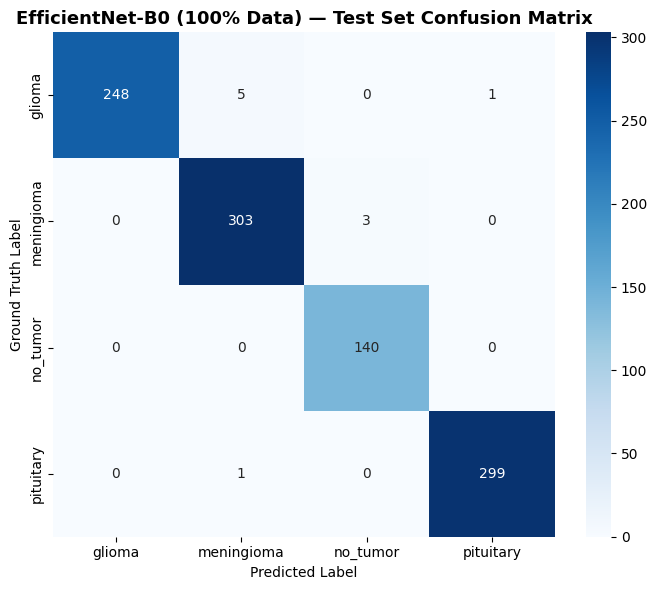

Confusion matrix saved to: /content/drive/MyDrive/medboard/weights/confusion_matrix_full.png


In [ ]:
from modules.clf_trainer import evaluate
import torch.nn as nn
import seaborn as sns

print('Evaluating best model checkpoint on holdout Test Set (1,000 images)...')
criterion = nn.CrossEntropyLoss()
device = torch.device(DEVICE_STR)

# Reload best saved checkpoint
best_model = build_classifier(num_classes=len(DEFAULT_CLASSES), pretrained=False).to(device)
best_model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
print(f'Model reloaded from: {CHECKPOINT_PATH}')

test_metrics = evaluate(
    model=best_model,
    loader=test_loader,
    criterion=criterion,
    device=device,
    class_names=DEFAULT_CLASSES,
)

print('\n' + '=' * 60)
print(f'TEST ACCURACY:  {test_metrics["accuracy"] * 100:.2f}%')
print(f'TEST MACRO-F1:  {test_metrics["macro_f1"]:.4f} ({test_metrics["macro_f1"] * 100:.2f}%)')
print(f'TEST LOSS:      {test_metrics["loss"]:.4f}')
print('=' * 60)

print('\nDetailed Classification Report:')
print(test_metrics['classification_report'])

# Plot Confusion Matrix
plt.figure(figsize=(7, 6))
sns.heatmap(
    test_metrics['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=DEFAULT_CLASSES,
    yticklabels=DEFAULT_CLASSES,
)
plt.title('EfficientNet-B0 (100% Data) — Test Set Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Ground Truth Label')
plt.tight_layout()

cm_path = os.path.join(WEIGHTS_DIR, 'confusion_matrix_full.png')
plt.savefig(cm_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Confusion matrix saved to: {cm_path}')

## Cell 8 — Export Weights for MedBoard Pipeline

In [ ]:
# Save as final release weights and full protocol weights
full_final_path = os.path.join(WEIGHTS_DIR, 'efficientnet_b0_full_brisc.pth')
if os.path.exists(CHECKPOINT_PATH):
    shutil.copy2(CHECKPOINT_PATH, FINAL_PATH)
    shutil.copy2(CHECKPOINT_PATH, full_final_path)
    print(f'Saved release weights to: {FINAL_PATH}')
    print(f'Saved archive weights to: {full_final_path}')
    print(f'File size: {os.path.getsize(FINAL_PATH) / (1024**2):.2f} MB')

if IS_COLAB:
    print('\nWeights saved to Google Drive:')
    print(f'  MyDrive/medboard/weights/{os.path.basename(FINAL_PATH)}')
else:
    print(f'\nWeights saved directly to: {FINAL_PATH}')

print('\nClassification model ready for MedBoard agent pipeline! \u2705')

Saved release weights to: /content/drive/MyDrive/medboard/weights/efficientnet_b0_brisc.pth
Saved archive weights to: /content/drive/MyDrive/medboard/weights/efficientnet_b0_full_brisc.pth
File size: 15.59 MB

Weights saved to Google Drive:
  MyDrive/medboard/weights/efficientnet_b0_brisc.pth

Classification model ready for MedBoard agent pipeline! ✅


## Cell 9 — Save Classification Metrics JSON & Text Report

In [ ]:
import json
from sklearn.metrics import classification_report

# Generate per-class dictionary report
report_dict = classification_report(
    test_metrics['targets'],
    test_metrics['predictions'],
    target_names=DEFAULT_CLASSES,
    output_dict=True,
    zero_division=0,
)

clf_metrics = {
    'model': 'EfficientNet-B0',
    'architecture': 'EfficientNet-B0 (Pretrained on ImageNet)',
    'protocol': '100% Training Corpus + Test Set Validation',
    'dataset': 'BRISC 2025 (Kaggle)',
    'parameters': int(count_parameters(best_model)['total']),
    'num_classes': len(DEFAULT_CLASSES),
    'classes': DEFAULT_CLASSES,
    'test_samples': len(test_metrics['targets']),
    'training': {
        'epochs_ran': len(history['train_loss']),
        'best_val_acc': round(float(max(history['val_acc'])), 4),
        'best_val_f1': round(float(max(history['val_f1'])), 4),
        'final_train_loss': round(float(history['train_loss'][-1]), 4),
        'final_train_acc': round(float(history['train_acc'][-1]), 4),
        'learning_rate': LEARNING_RATE,
        'lr_scheduler': 'cosine',
    },
    'metrics': {
        'test_loss': round(float(test_metrics['loss']), 4),
        'test_accuracy': round(float(test_metrics['accuracy']), 4),
        'test_accuracy_percentage': round(float(test_metrics['accuracy']) * 100, 2),
        'test_macro_f1': round(float(test_metrics['macro_f1']), 4),
        'test_macro_f1_percentage': round(float(test_metrics['macro_f1']) * 100, 2),
    },
    'per_class_metrics': {
        cls_name: {
            'precision': round(float(report_dict[cls_name]['precision']), 4),
            'recall': round(float(report_dict[cls_name]['recall']), 4),
            'f1_score': round(float(report_dict[cls_name]['f1-score']), 4),
            'support': int(report_dict[cls_name]['support']),
        }
        for cls_name in DEFAULT_CLASSES
    },
    'confusion_matrix': test_metrics['confusion_matrix'].tolist(),
}

# 1. Save JSON metrics
clf_json_path = os.path.join(WEIGHTS_DIR, 'classification_full_metrics.json')
with open(clf_json_path, 'w') as f:
    json.dump(clf_metrics, f, indent=2)
print(f'Metrics JSON saved to: {clf_json_path}')

# 2. Save text classification report
clf_txt_path = os.path.join(WEIGHTS_DIR, 'classification_full_report.txt')
with open(clf_txt_path, 'w') as f:
    f.write(test_metrics['classification_report'])
print(f'Text report saved to:   {clf_txt_path}')

print('\nStructured Summary:')
print(json.dumps(clf_metrics['metrics'], indent=2))

Metrics JSON saved to: /content/drive/MyDrive/medboard/weights/classification_full_metrics.json
Text report saved to:   /content/drive/MyDrive/medboard/weights/classification_full_report.txt

Structured Summary:
{
  "test_loss": 0.0529,
  "test_accuracy": 0.99,
  "test_accuracy_percentage": 99.0,
  "test_macro_f1": 0.9899,
  "test_macro_f1_percentage": 98.99
}
